<a href="https://colab.research.google.com/github/davidsmall-Durham/EDS-Practicals/blob/main/EDS_Practical_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Practical 7 - Model-Data comparison using Google Earth Engine**

### *Background*
Global Climate Models (GCMs) from the Coupled Model Intercomparison Project Phase 6 (CMIP6) are essential tools for simulating future climate scenarios. However, their raw outputs typically feature coarse spatial resolutions (often $>100\text{ km}$), making them less suited for localised climate impact assessments. To bridge this gap, the **[NASA NEX-GDDP-CMIP6](https://www.nccs.nasa.gov/data-collections/nex-gddp-cmip6/)** dataset provides globally downscaled, high-resolution (approx. $25\text{ km}$) climate projections derived from the raw CMIP6 outputs.

The historical (e.g., 1850-2014) simulations within the NEX-GDDP-CMIP6 archive have undergone statistical downscaling and bias correction. This process applies two major mathematical corrections anchored to a historical observational baseline, the [Global Meteorological Forcing Dataset (GMFD)](https://gdex.ucar.edu/datasets/d314000/). The derived corrections are then applied to the future projections.

*   **Statistical Downscaling**: The spatial scale of the coarse GCMs is interpolated and disaggregated to match the finer grid of the GMFD.  
*   **Bias Correction**: Systematic errors in the GCM simulations (e.g., a tendency for a model to underestimate winter minimum temperatures) are mathematically aligned with the statistical distribution of the GMFD observational data.

While bias correction improves the localised utility of climate data, the corrected historical simulation are no longer independent of the training dataset (GMFD). Thus evaluating the models against GMFD is an example of circular validation. To evaluate model performance we must assess against an independent observational baseline.

In this practical, we will validate a selection of NEX-GDDP-CMIP6 models using the **[ERA5 reanalysis product](https://www.ecmwf.int/en/era5-land)**, a global atmospheric reanalysis dataset produced by the ECMWF. ERA5 combines physics-based models with observations, and was not used in processing CMIP outputs as part of the NEX dataset's generation. It is therefore a completely independent baseline that can be used for validation.


###*Aims*
The overall aim for this practical is to look at model-data comparison by comparing historical rainfall data with model simulatiuons of the same period. We are going to continue analysing the Asian Monsoon but with a specific focus on the country of India.

In this practical we will:
1. Define two seperate image collections with the same spatiotemporal extents.
2. Understand the rationale and workflows involved in aligning our datasets.
3. Learn how to map simple functions across multiple items in parallel.
4. Calculate metrics to assess overall model-data agreement.



##**Setup**

As with our previous notebooks our first job is to set ourselves up with the packages and permissions we need to perform our task.


In [ ]:
#@title ##### Install and import packages
!pip install geemap -q cartopy -q xarray -q netcdf4 -q rioxarray -q

import ee
import geemap
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import rioxarray # Enables xarray to read GeoTIFFs natively
import os # enables operating system-dependent functionality, like reading or writing to the file system

In [ ]:
#@title #####Authenticate Google Earth Engine
# Trigger the authentication flow
ee.Authenticate()

# Initialize the Earth Engine module
ee.Initialize(project='eds-practical-2-testing') # Students will need a cloud project ID (need to get them to set this up before hand)

##**Section 1: Setting up our filtered image collections**

In this practical we are going to be comparing two different datasets so we will need to create two different filtered image collections (N.B., links point to the GEE data catalog pages).

* **model output**: [NASA NEX-GDDP-CMIP6](https://developers.google.com/earth-engine/datasets/catalog/NASA_GDDP-CMIP6) image collection.

* **observational data**:  [ERA5](https://developers.google.com/earth-engine/datasets/catalog/ECMWF_ERA5_DAILY) image collection.


We will focus on precipiation over one specific country, India. Thus instead of filtering our Image Collections using a set of coordinates we will instead filter an AOI using the national borders of India.

We obtain a geometry for this boundary from an `ee.FeatureCollection`. We will use the [USDOS](https://developers.google.com/earth-engine/datasets/catalog/USDOS_LSIB_SIMPLE_2017) feature collecton and extract the boundary for India

Our 30-year window for comparison will be 1985-2014. We are going to focus our analysis on the monsoon period therefore we further filter our collections to the appropriate months.

To filter the NEX collection we need to define the names of the CMIP models we will analyse. We have chosen four models from CMIP6, see [here](https://developers.google.com/earth-engine/datasets/catalog/NASA_GDDP-CMIP6#image-properties) for a full list of the models included in this data set. We need this to be in a format GEE can work with, specifically an `ee.List`.


In [ ]:
#@title ##### This cell defines our initial filter parameters
# Filter for India boundary

# Define 30-year historical baseline window

# List of models to analyse (we define it as a python list then convert it to an Earth Engine list)


Now that we have defined the filters we can go ahead and set up our filtered Image Collections. We can refer to these as our base image collections.

In [ ]:
#@title ##### This code cell sets up our base image collections
# Load and Filter NEX-GDDP-CMIP6


# Load and Filter ERA5-Land



# We want to ensure that we have a compatible number of images in each collection
# otherwise we might run into trouble aligning them later on


NEX Images found for India: 14640
ERA5 Images found for India: 3660


###**Questions**

1. What dimensions does our `nex_collection` have?
2. How many individual images does it contain?

It would be worth checking that we have a compatible number of images in each collection otherwise we might run into trouble aligning them later on. **Can you write another line of code in the code cell above to do this?**

3. Do the number of images in each collection allign?

Looking at the metadata for each dataset on the GEE catalog,

4. What are the units for our precipitation variables?
5. What is the spatial resolution of each dataset? Is it the same?

##**Section 2: Comparing the spatial resolution of our data sets**


Before we set up the specifics of the analysis it is worth doing a visual comparison of our two datasets in terms of their spatial resolution. This is because the GDDP-CMIP data has all been regridded to $0.25^\circ \times 0.25^\circ$ where as the ERA5-Land data is natively at $0.1^\circ \times 0.1^\circ$ resolution. We can visualise the difference in resolution by making a quick map using the `geemap` library. Toggle between the layers to see the difference.

In [ ]:
#@title ##### Visualise difference in resolution

# Select a specific day to visualize the spatial resolution contrast then select images from each collection
target_date = '2010-07-15'

nex_sample = (nex_collection
              .filterDate(target_date) # This is a shorthand version of .filter(ee.Filter.date()) - it does the same thing
              .first()                 # Selects the first image with this date (in case we had any overlap)
              .clip(geometry))         # Its ok to clip now as we are down to a single image

era5_sample = (era5_collection
               .filterDate(target_date)
               .first()
               .clip(geometry))

# Define visualization parameters
# Shared color palette going from light blue to deep blue
rain_palette = ['#f7fbff', '#deebf7', '#c6dbef', '#9ecae1', '#6baed6', '#4292c6', '#2171b5', '#084594']

# This bit of code sets the visualisation parameters for our era5 example
# Precipitation in ERA5 is in meters. 0 - 0.1m (100 mm) of rain per day
vis_params_era5 = {
    'min': 0.0,
    'max': 0.1,
    'palette': rain_palette
}

# And now for out NEX-GDDP example
# Precipitation in NEX-GDDP is in kg/m2/s (mm/s).
vis_params_nex = {
    'min': 0.0,
    'max': 0.1,
    'palette': rain_palette
}

# Create the interactive map and center over Western Europe
Map = geemap.Map(height='800px', width='800px')
Map.centerObject(geometry, zoom=4)

# Add the ERA5 Layer (Fine resolution: ~11km)
Map.addLayer(era5_sample, vis_params_era5, f'ERA5 Precip ({target_date})')

# Add the NEX Layer (Coarse resolution: ~28km)
Map.addLayer(nex_sample, vis_params_nex, f'NEX-GDDP-CMIP6 Precip ({target_date})')

# Add a layer control panel to the map so we can toggle them
Map.add_layer_control()

# Add base layer selector tool
Map.add("basemap_selector")

# Display the map
Map

Map(center=[22.76232877465696, 79.57964433730972], controls=(WidgetControl(options=['position', 'transparent_b…

**TASK**

We can see precipitation for our ERA5 layer but the NEX-GDDP layer is just a solid white polygon.

The map has rendered and Python has not given us any errors so our code is ostensibly correct but it isn't displaying correctly. There are clues in the comments above. You will need to change one line of code to a value of 0.001 to get a better visulisation.


 **Decide what line of code to change, then re-run the code cell**

*This highlights one issue with supposedly Analysis Ready Data. Even though both layers contain daily precipitation values, they are currently incompatible because different institutions choose different reporting conventions.*

We must always check the metadata!!

---

**Assuming we can now see patterns in both layers**

Because ERA5-Land ($\sim 11\text{ km}$) has a finer resolution than NEX ($\sim 28\text{ km}$), we have multiple finer ERA5 pixels overlapping a single, larger NEX pixel. We therefore, at some point, need to align our datasets to the same spatial resolution.

Choosing whether to upscale ERA5 (make fine data coarser) or downscale NEX (make coarse data finer) is an important decision with implications for the physical realism of our data. Also, when designing our workflow we need to consider what is the most computationally efficient approach.

**Questions**
1. Why should we upscale our observations rather than downscale our model results?
2. Should we undertake this re-gridding now, or later in our workflow? And why?


##**Section 3: Construcing our analysis**

We will keep it simple and ask the question:


***"Overall, how well do these models represent rainfall during the monsoon season in India during the epriod 1985-2104?"***

Because we are making a general overall assessment of model performance we will collapse the time dimensions of our collections to a single long term average.

We first calculate the average for our 30 year ERA observational period (1985-2014) in the same way as we did in the previous practical.

In [ ]:
#@title ##### This cell calculates JJAS precipitation (1985-2014) for the observations (ERA5)

# Grab the native projection from a single raw ERA5 image and use this to set
# the projection for our long-term average


# Sum to get a 30-year total, convert m or rain to mm, divide by number of years to get an average, and then clip


# And set projection metadata (needed for export)


**Upscaling our ERA5 data to NEX resolution**

We have now reduced our base ERA5 collection into a single image, the average total monsoon rainfall (JJAS) for the period 1985-2014. A good rule of thumb is, **always reduce temporally before regridding**. We ahve reduced as much as is practical thus we should now reproject (upscale) our ERA5 image to the same spatial resolution as our model data.

In [ ]:
#@title ##### This cell grabs the NEX grid and reprojcts our long-term ERA5 average onto it

# Grab a template projection from NEX to upscale ERA

# Regrid ERA5 to the coarser CMIP6 scale
# This is our static baseline used inside the function below




After reprojecting our long-term ERA5 JJAS average we have a baseline value that we can compare our model outputs to. Before we calculate any metrics let's do a visual inspection of the spatial pattern of model bias by differencing the observational average with each individual model average (in effect we are simply subtracting 2D rasters).

Model bias is defined simply as:

$$ Bias_i = Model_i - Observation_i$$

Where $Model_i$ and $Observation_i$ are the modelled and obsered rainfall totals for grid cell *i*.

---
**Mapping a function across our models**

If we write a set of instructions and package them all up as a named object (called a function) we can use that function name with the `.map()` command to tell GEE to execute those instruction on every item that is passed with the function *all at once*.

Earlier we made a list of the models we were interested in. We can combine this list with the `.map()` command to tell GEE to excute whatever instructions we give it on our model list. I.e.:

```
models_ee.map(OUR INSTRUCTIONS)
```
We can conceptualise this a bit like a loop. The commands will be carried out on every item within the list. The key difference being it is done in parallel and GEE can already see ALL server side variables, such as `nex.collection` and `era5_JJAS_regridded`. Therefore we don't need to pass these variables to the function. We ONLY pass the list for GEE to work through.

Therefore we write instructions that do our desired analysis (i.e. compute the long term JJAS average precipitation). We do this by explicitly writing our instructions as a Python function.

In [ ]:
#@title ##### In this code cell we write our function


Now that our instructions are written, we can plug them into the `.map()` command. GEE will distribute this function to separate servers to process ALL of our models at the exact same time.

Remember, we still wont't trigger any computation until we try to export the results.

In [ ]:
#@title ##### Now we map the function and collate the results

# Pass our model list into the map command with our function as the instructions


# Convert the resulting list back into an ImageCollection so we can work with it


##**Section 4: Exporting the results**

Before we export anything we are going to mount our Google Drive. The reason for doing so now is so we can include  code in our export cell to check if the files already exist and save us from redundantly exporting again if we re-run this notebook.

In [ ]:
#@title ##### This cell mounts your Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In the last notebook we set up two individual export tasks to export our results as GeoTiff files. We could do this again but another way to do this is to write a Python loop to set off the export tasks.


In [ ]:
#@title ##### This is our export command loop


Once the exported files are downloaded into your Google Drive we are ready to plot. Becasue each panel is essentially the same (plotting a different dataset but in the same exact way) we will use a loop to plot our data in a four panel figure. This requires less code that writing out plotting instructions for each panel individually.

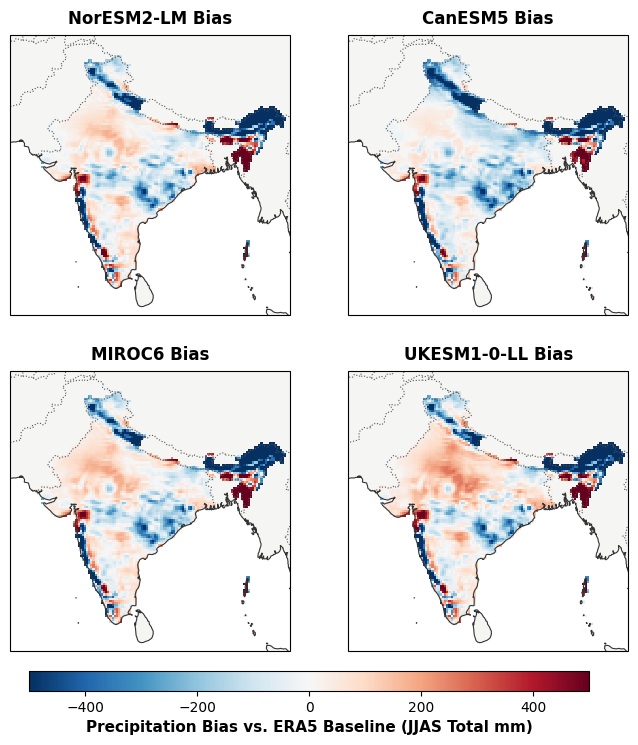

In [ ]:
#@title ##### This code cell loads the GeoTiffs into xarray and plots a nice figure

# We had already defined our model names but will do so again for readability
models = ['NorESM2-LM', 'CanESM5', 'MIROC6','UKESM1-0-LL']

# Initialize a 2x2 subplot figure mapped to a standard Lat/Lon projection
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8, 8),
                         subplot_kw={'projection': ccrs.PlateCarree()})

axes = axes.flatten() # Flattens the 2D 'axes' array (2x2) into a 1D Python list (4 elements) for easy looping

#  Set up uniform color limits and a divergent colormap
# 'RdBu_r' is reversed: Blue = Underestimating rain, Red = Overestimating rain
vmin, vmax = -500, 500 # we could improve this by calcualting vmin and vmax programatically
cmap = 'RdBu_r'

# Now that the figure is set up we write our loop to iterate through (i times)
# the model list and plot each one in the corresponding axes.

# When we use enumerate(), Python sets a counter alongside each item in our
# list. It turns our list of strings into pairs of (index, item).
# During our loop, the variables i and model_name change like this:
# Iteration 1: i = 0, model_name = 'NorESM2-LM'
# Iteration 2: i = 1, model_name = 'CanESM5'
# Iteration 3: i = 2, model_name = 'MIROC6'
# Iteration 4: i = 3, model_name = 'UKESM1-0-LL'

for i, model_name in enumerate(models):
    filename = f"{model_name}_Monsoon_Bias_1985_2014.tif"
    filepath = os.path.join(DATADIR, filename)

    # Now open the file with xarray
    # masked=True automatically converts Earth Engine NoData values into NaNs
    # Remember we"squeeze" away any dimensions wiith length 1
    da = rioxarray.open_rasterio(filepath, masked=True).squeeze()

    # Set the axes to plot in, and zoom in manually [min_lon, max_lon, min_lat, max_lat]
    ax = axes[i]
    ax.set_extent([65, 98, 5, 38], crs=ccrs.PlateCarree())

    # Add geographic features
    ax.add_feature(cfeature.LAND, facecolor='#f5f5f3', zorder=0)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor='#333333', zorder=2)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.8, edgecolor='#555555', zorder=2)

    # xarray handles geographic coordinates natively.
    # We set add_colorbar=False because we will build a shared one at the bottom.
    im = da.plot.imshow(
        ax=ax,
        transform=ccrs.PlateCarree(),
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        zorder=1,
        add_colorbar=False  # Suppress individual colorbars so we can build a shared one
    )

    # Add label to each panel
    ax.set_title(f"{model_name} Bias", fontsize=12, fontweight='bold', pad=8)

# Add a shared colorbar at the bottom of the layout
cbar_ax = fig.add_axes([0.15, 0.06, 0.7, 0.025])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Precipitation Bias vs. ERA5 Baseline (JJAS Total mm)', fontsize=11, fontweight='bold')

# Save the publication-ready plot
plt.savefig('Monsoon_Model_Bias.png', dpi=300, bbox_inches='tight')
plt.show()

####**Question**


1.   Can you describe the overall patterns of bias, are there any areas that are systematically biased in more than one model?


## **Section 5: A quantitative estimate of model performance**

To determine which climate model performs "best" at simulating monsoon precipitation, we need to move beyond visual inspection of bias maps and compute spatial aggregate statistics. As mentioned in the lecture, "best" is rarely determined by a single metric. Instead, a model is evaluated on its ability to capture absolute overall offsets, magnitude, spatial distribution (patterns), and variability.

To compare each model's monsoon map against our ERA5 baseline, there are a range of aggregate metrics across we could calculate inlcuding:

* **Percent Bias (PBIAS)**: Measures the tendency of the simulated data to be larger or smaller than the observations, expressed as a percentage. A positive value means the model systematically overestimates precipitation (wet bias); negative means it underestimates (dry bias).

* **Mean Absolute Error (MAE)**: Measures the average magnitude of the errors without considering their direction. This prevents large positive errors in one region from canceling out large negative errors in another.

* **Root Mean Squared Error (RMSE)**: Similar to MAE, but it squares the errors before averaging them. This penalizes large but localised errors heavily.

* **Spatial Pattern Correlation (Pearson $r$)**: Measures how well the model captures the geographical features of precipitation (e.g., heavy rain along mountain ranges, dry zones in rain shadows). A value of 1 means perfect spatial alignment, even if the absolute amounts are off.

* **Standard Deviation Ratio ($SD_{model} / SD_{ref}$)**: Evaluates if a model  captures the spatial variability or contrast of the landscape. A ratio of 1.0 is perfect. A ratio $< 1$ means the model's output is too "smooth" or uniform; $> 1$ means the model has exaggerated spatial extremes.

Choosing the most appropriate metrics depends on how the data will be used. If intense but rare rainfall events matter to the end user then **RMSE** may be a better choice as it heavily penalises models that poorly capture these. If long term water availabilty is more of a concern then **PBIAS** may be better as its not skewed by a few extreme events.

Similarly it may be more important that the model accurately predicts the location of the rain rather than the total amount. In this case the **spatial pattern correlation** is important. These help us understand if a model captures the physics of the region (like orographic rainfall over mountains) and whether it preserves the contrast between wet and dry zones rather than smoothing out real rainfall gradients.

---

We are going to calculate two aggregate spatial statistics for our AOI. Specifically, we will calculate the percent bias (**PBIAS**) and a spatial correlation pattern (**Pearson $r$**)

Firstly we will calcualte the average monsoon rainfall in all four models for the period 1985-2014.

In [ ]:
#@title ##### Here we define and map the function to calculate average monsoon rainfall in our model data



We now write a new function that will be mapped across each individual image in `absolute_collection` to calculate **PBIAS** and **Pearson $r$**.

For each individual execution of this function (i.e., for our four different models), we need to compare `model_image` and `era5_JJAS_regridded`. Because Earth Engine's reducer tools operate on a single image, we use `.addBands()` to combine them into a single multi-band `ee.Image`.

---
The formula for **PBIAS** is:

$$PBIAS = \left[ \frac{\sum_{i=1}^{n} (Mod_i - Obs_i)}{\sum_{i=1}^{n} Obs_i} \right] \times 100$$

Where; $Mod_i$ and $Obs_i$ are the $i$th modelled and observed values respectively and $n$ is the total number of data points.

In the code we first add up all precipitation across the whole country for both the model and ERA5 using `.sum()`. Then, we use the Percent Bias formula.

---

The formula for **Pearson $r$** is:

$$r = \frac{\sum_{i=1}^{n} (Mod_i - \bar{Mod})(Obs_i - \bar{Obs})}{\sqrt{\sum_{i=1}^{n} (Mod_i - \bar{Mod})^2 \sum_{i=1}^{n} (Obs_i - \bar{Obs})^2}}$$

Where; **$\bar{Mod}, \bar{Obs}$** are the sample means of the datasets.

In the code this is handled by Earth Engine's built-in tool (`ee.Reducer.pearsonsCorrelation()`)

In [ ]:
#@title #### Here we define a function to calcualte our metrics


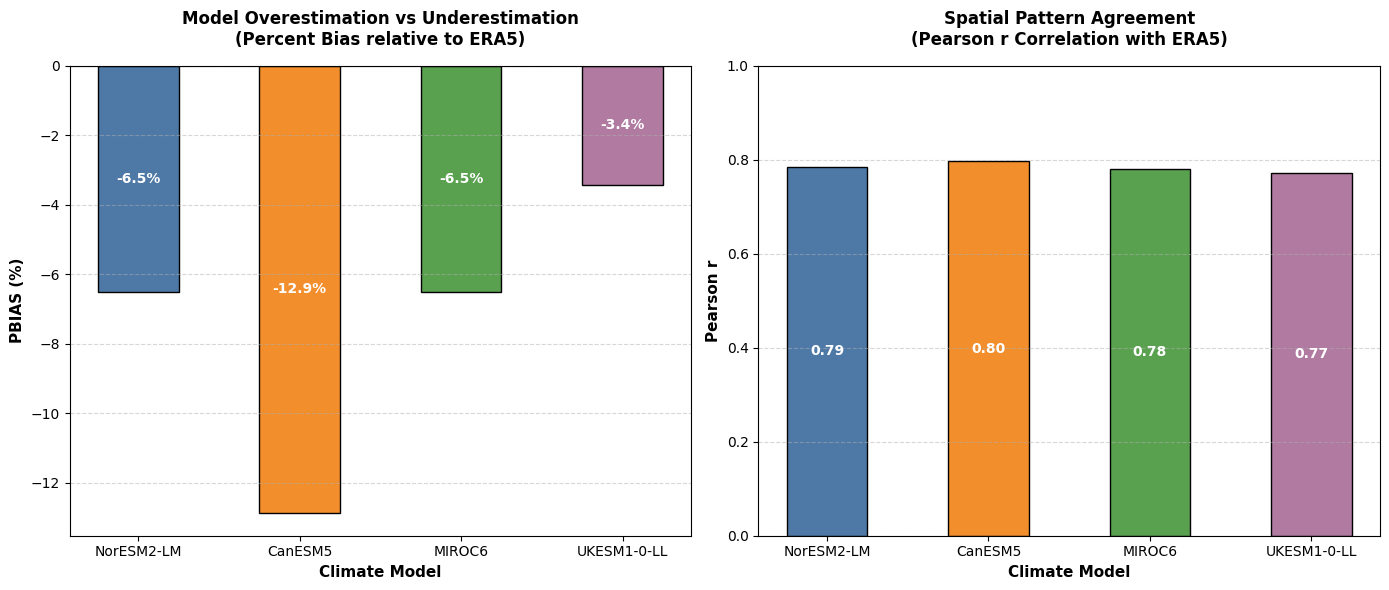

In [ ]:
#@title ##### This cell plots our server-side metrics as a simple bar chart

# Extract model names and metric values from server-side results
models_list = [feat['properties']['Model'] for feat in metrics_results]
pbias_list = [feat['properties']['PBIAS (%)'] for feat in metrics_results]
pearson_list = [feat['properties']['Pearson r (Spatial)'] for feat in metrics_results]

# Define a shared color palette for your models
shared_colors = ['#4e79a7', '#f28e2b', '#59a14f', '#b07aa1']

# Initialize a 1-row, 2-column subplot figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Percent Bias (PBIAS) Bar Chart
bars1 = ax1.bar(models_list, pbias_list, color=shared_colors, edgecolor='black', width=0.5)
ax1.axhline(0, color='black', linestyle='-', linewidth=1.5)
ax1.set_title('Model Overestimation vs Underestimation\n(Percent Bias relative to ERA5)', fontsize=12, fontweight='bold', pad=15)
ax1.set_ylabel('PBIAS (%)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Climate Model', fontsize=11, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Subplot 2: Spatial Pearson Correlation (r) Bar Chart
bars2 = ax2.bar(models_list, pearson_list, color=shared_colors, edgecolor='black', width=0.5)
ax2.set_title('Spatial Pattern Agreement\n(Pearson r Correlation with ERA5)', fontsize=12, fontweight='bold', pad=15)
ax2.set_ylabel('Pearson r', fontsize=11, fontweight='bold')
ax2.set_xlabel('Climate Model', fontsize=11, fontweight='bold')
ax2.set_ylim(0, 1.0) # Standard correlation bounds
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# Add text labels inside the center of the bars
ax1.bar_label(bars1, labels=[f"{x:+.1f}%" for x in pbias_list], label_type='center', color='white', fontweight='bold', fontsize=10)
ax2.bar_label(bars2, labels=[f"{x:.2f}" for x in pearson_list], label_type='center', color='white', fontweight='bold', fontsize=10)

# Final layout adjustments and display
plt.tight_layout()
plt.show()

### **Questions**

1. Do our models underestimate or overestimate the total amount of Monsoon rainfall?
2. Considering the metrics above, which model performs the "best" overall?
3. The spatial correlation for each model is almost exactly the same, why might this be? (Refer back to the introduction to this notebook).

---

### **TASK**

Now we have worked through the baseline notebook for India,you can test your skills on a new region and expand your analysis framework.

Your objective is to produce code to evaluate a completely different region and a new set of climate models, while also computing an additional error metric to capture localised extremes.

#### **Step 1: Choose a New Study Region**

* Change the national boundary filter from India to a new country with complex topography and distinct rainfall patterns (e.g., **Pakistan** or **Vietnam**).
* *Hint:* Look at how the region filter is set up using the `USDOS/LSIB_SIMPLE/2017` feature collection and update the country name property (`country_na`).

#### **Step 2: Select 4 New CMIP6 Models**

* Replace the original model list (`['NorESM2-LM', 'CanESM5', 'MIROC6', 'UKESM1-0-LL']`) with four different models available in the NASA NEX-GDDP-CMIP6 catalog.


#### **Step 3: Introduce a New Metric (RMSE)**

* In Section 5, the notebook calculates Percent Bias (PBIAS) and Spatial Pearson $r$.
* Add the **Root Mean Squared Error (RMSE)** to your analysis function.

* Add your new RMSE column to the `metrics_summary` dictionary so it displays alongside PBIAS and Pearson $r$ in your final summary table.

---

### **Questions**

1. How do the spatial bias maps look in your new region compared to India? Do you see stronger spatial disagreement or localised extremes over mountain ranges?
2. Did your new set of four models perform better or worse based on the **RMSE** metric? Why might RMSE give a harsher assessment of model performance than PBIAS?